# Лабораторная работа №4: Диффузионные модели

## Студент: Ерзикова Е.А., группа 6233-010402D

## Цель
Изучить принципы работы диффузионных моделей на примере Stable Diffusion и DDPM, научиться управлять процессом генерации.

## Теория
- Прямой и обратный процесс в диффузионных моделях.
- Отличие DDPM от GAN.
- Stable Diffusion и использование текстовых эмбеддингов.

## Задания
Часть 1. Stable Diffusion:
1. Использовать предобученную модель (HuggingFace diffusers).
2. Сгенерировать изображения по разным промптам.
3. Исследовать влияние параметров (guidance scale, количество шагов).

Часть 2. DDPM:
1. Реализовать упрощённый DDPM (по готовому туториалу).
2. Обучить модель на MNIST или CIFAR-10.
3. Визуализировать процесс: добавление шума и восстановление.

## Вопросы
1. Чем диффузионные модели отличаются от GAN?
2. Почему количество шагов важно для качества?
3. Какие ещё задачи (помимо генерации картинок) можно решать диффузионными моделями?

## Отчёт
- Иллюстрации сгенерированных изображений.
- Графики/визуализации процесса диффузии.
- Ответы на вопросы.

# Теория: Диффузионные модели



## 1. Прямой и обратный процесс в диффузионных моделях

В основе диффузионных моделей лежит идея **постепенного разрушения и последующего восстановления данных**, которая реализуется через два процесса:

### Прямой процесс (Forward Process)

Это **марковский процесс**, в котором к исходному изображению $x_0$ шаг за шагом (обычно за $T = 1000$ шагов) добавляется гауссов шум.

- На каждом шаге $t$ изображение становится чуть более зашумлённым.
- В пределе, когда $t \to T$, исходная структура полностью исчезает, и изображение превращается в **чистый случайный шум** (стандартное нормальное распределение).
- Этот процесс **не обучается** — он задан математически.

### Обратный процесс (Reverse Process)

Это процесс **денойзинга**. Задача нейросети (обычно **U-Net**) — научиться обращать прямой процесс.

- На каждом шаге модель получает зашумлённое изображение и текущий шаг времени $t$.
- Цель модели — **предсказать и вычесть добавленный шум**.
- Начиная с чистого шума (на шаге $T$), модель постепенно шаг за шагом восстанавливает осмысленное изображение, пока не достигнет шага $t = 0$.



## 2. Отличие DDPM от GAN

Хотя обе архитектуры являются генеративными, принципы их работы кардинально отличаются:

| Критерий | **GAN** | **DDPM** |
|---|---|---|
| **Принцип обучения** | Состязательная игра двух сетей: Генератора (создаёт картинки) и Дискриминатора (отличает реальные от поддельных). Процесс может быть крайне нестабильным. | Решение задачи **регрессии** — предсказывать шум. Обучение более стабильное и предсказуемое. |
| **Коллапс мод (Mode Collapse)** | Склонны генерировать лишь ограниченный набор вариаций (например, только одни и те же лица), игнорируя остальные данные. | Лучшее покрытие распределения — генерируют более разнообразные результаты. |
| **Скорость генерации** | Один прямой проход сети — **очень быстро**. | Итеративный процесс из десятков или сотен шагов — **медленнее**. |
| **Качество** | Могут страдать от локальных артефактов, но дают резкие картинки. | Высокая глобальная когерентность и фотореалистичность; при малом числе шагов могут давать «мыльные» изображения. |



## 3. Stable Diffusion и использование текстовых эмбеддингов

**Stable Diffusion** — это модель, основанная на архитектуре **Latent Diffusion Model (LDM)**. Её главные особенности:

### Работа в латентном пространстве

- В отличие от DDPM, которые добавляют шум напрямую в пиксели (что требует огромных вычислительных ресурсов), Stable Diffusion использует **автоэнкодер (VAE)**.
- Он сжимает изображение в компактное латентное представление (**в 8 раз меньше по ширине и высоте**).
- Весь процесс диффузии происходит именно в этом сжатом пространстве — это делает генерацию быстрой и доступной для обычных видеокарт.

### Текстовые эмбеддинги (Text Conditioning)

- Чтобы модель понимала, что мы просим нарисовать, текст промпта пропускается через **текстовый энкодер** (в SD 1.5 используется **CLIP**).
- Энкодер превращает слова в числовые векторы — **эмбеддинги**.

### Механизм Cross-Attention

- Эти текстовые эмбеддинги внедряются в блоки **U-Net** через механизм **перекрёстного внимания (cross-attention)**.
- Благодаря этому на каждом шаге денойзинга сеть «сверяется» с текстом и понимает, какие именно объекты (например, *«капибара»*, *«горячий источник»*, *«неон»*) и в каком стиле ей нужно формировать из шума.

## Установка зависимостей

In [ ]:
!pip install -q --upgrade diffusers transformers accelerate safetensors
!pip install -q matplotlib tqdm

import torch

print("PyTorch:", torch.__version__)
print("CUDA доступна:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(f"Память: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    print("Включите GPU")

PyTorch: 2.11.0+cu130
CUDA доступна: True
GPU: Tesla T4
Память: 15.6 GB


## Загрузка модели Stable Diffusion

In [ ]:
import os, gc
import torch
from pathlib import Path
from PIL import Image
from IPython.display import display, clear_output
from diffusers import StableDiffusionPipeline
import matplotlib.pyplot as plt

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
OUTPUT_DIR = Path("sd_results")
OUTPUT_DIR.mkdir(exist_ok=True)

print(">>> Загрузка Stable Diffusion 1.5 ")
pipe = StableDiffusionPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    torch_dtype=DTYPE,
    safety_checker=None,
    requires_safety_checker=False,
).to(DEVICE)

pipe.enable_attention_slicing()
try:
    pipe.enable_vae_slicing()
except Exception:
    pass
pipe.set_progress_bar_config(disable=True)

def make_grid(images, cols=3, titles=None, figsize=None, save_path=None, suptitle=None):
    n = len(images)
    rows = (n + cols - 1) // cols
    if figsize is None:
        figsize = (cols * 3.2, rows * 3.4)
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    axes = axes.flatten() if n > 1 else [axes]
    for i in range(len(axes)):
        axes[i].axis("off")
        if i < n:
            axes[i].imshow(images[i])
            if titles is not None:
                axes[i].set_title(titles[i], fontsize=10)
    if suptitle:
        fig.suptitle(suptitle, fontsize=13)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=140, bbox_inches="tight")
    plt.show()

>>> Загрузка Stable Diffusion 1.5 


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

## Генерация изображений по разным промптам

Описание: Генерация 6 изображений с капибарой в разных стилях при фиксированных параметрах (guidance_scale=7.5, steps=50).

Промпты:


1.   Фотореалистичный крупный план капибары, отдыхающей в горячем источнике, поднимается пар, фото в стиле National Geographic.

1.   Капибара в крошечном шлеме астронавта, парящая в космосе, кинематографичное освещение, высокая детализация.

1.   Капибара сидит в уютной кофейне и читает газету, стиль Studio Ghibli, мягкие цвета.
2.   Картина маслом: капибара в образе аристократа эпохи Возрождения с золотым кубком, драматичное освещение.


2.   Капибара-диджей на вечеринке в стиле киберпанк с неоновым светом, дождь, кинематографично, 8k, высокая детализация.


2.   Акварельный рисунок: капибара сидит среди лотосов в японском саду, влияние укиё-э, мягкие пастельные тона.



[1/6] A photorealistic close-up of a capybara relaxing in a hot spring, steam rising, National Geographic photo
[2/6] A capybara wearing a tiny astronaut helmet floating in space, cinematic lighting, highly detailed
[3/6] A capybara sitting in a cozy coffee shop reading a newspaper, Studio Ghibli style, soft colors
[4/6] An oil painting of a capybara as a Renaissance nobleman, holding a golden goblet, dramatic lighting
[5/6] A capybara DJ at a neon-lit cyberpunk rave, glowing lights, rain, cinematic, 8k, highly detailed
[6/6] A watercolor painting of a capybara sitting among lotus flowers in a Japanese garden, ukiyo-e influence, soft pastel colors


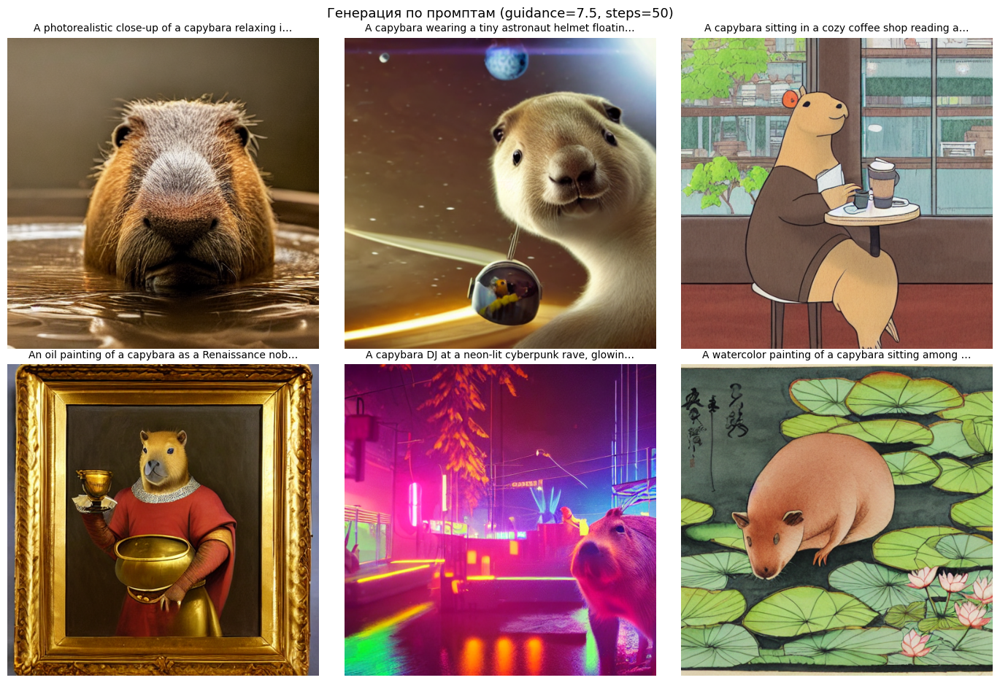

In [ ]:
prompts = [
    "A photorealistic close-up of a capybara relaxing in a hot spring, steam rising, National Geographic photo",
    "A capybara wearing a tiny astronaut helmet floating in space, cinematic lighting, highly detailed",
    "A capybara sitting in a cozy coffee shop reading a newspaper, Studio Ghibli style, soft colors",
    "An oil painting of a capybara as a Renaissance nobleman, holding a golden goblet, dramatic lighting",
    "A capybara DJ at a neon-lit cyberpunk rave, glowing lights, rain, cinematic, 8k, highly detailed",
    "A watercolor painting of a capybara sitting among lotus flowers in a Japanese garden, ukiyo-e influence, soft pastel colors",
]

images = []
for i, prompt in enumerate(prompts):
    print(f"[{i+1}/{len(prompts)}] {prompt}")
    img = pipe(
        prompt,
        num_inference_steps=50,
        guidance_scale=7.5,
        generator=torch.Generator(device=DEVICE).manual_seed(42 + i),
    ).images[0]
    img.save(OUTPUT_DIR / f"prompt_{i:02d}.png")
    images.append(img)

make_grid(
    images,
    cols=3,
    titles=[p[:50] + "…" for p in prompts],
    figsize=(14, 9.5),
    save_path=OUTPUT_DIR / "grid_prompts.png",
    suptitle="Генерация по промптам (guidance=7.5, steps=50)",
)

Stable Diffusion 1.5 превосходно справляется с переносом художественных стилей (Ghibli, Ренессанс, Укиё-э). Модель понимает эстетику, освещение и палитру.

Модель плохо понимает сложную физику и пространственные отношения. Она отлично рисует объекты по отдельности (капибара, шлем, кубок), но когда их нужно совместить (надеть шлем, взять кубок), часто возникают логические ошибки и артефакты.

Наделение животных человеческими чертами (сидеть за столом, быть аристократом) дается модели легко, но анатомия конечностей при этом часто ломается (как с лапой, держащей кофе).

Значение guidance=7.5 позволило сохранить баланс между креативностью и следованием промпту (картинки не перенасыщены и не «пластилиновые»), а steps=50 обеспечило высокую детализацию текстур (шерсть, вода, мазки масла).

## Исследование влияния guidance_scale

guidance_scale = 1.0
guidance_scale = 3.0
guidance_scale = 5.0
guidance_scale = 7.5
guidance_scale = 10.0
guidance_scale = 15.0


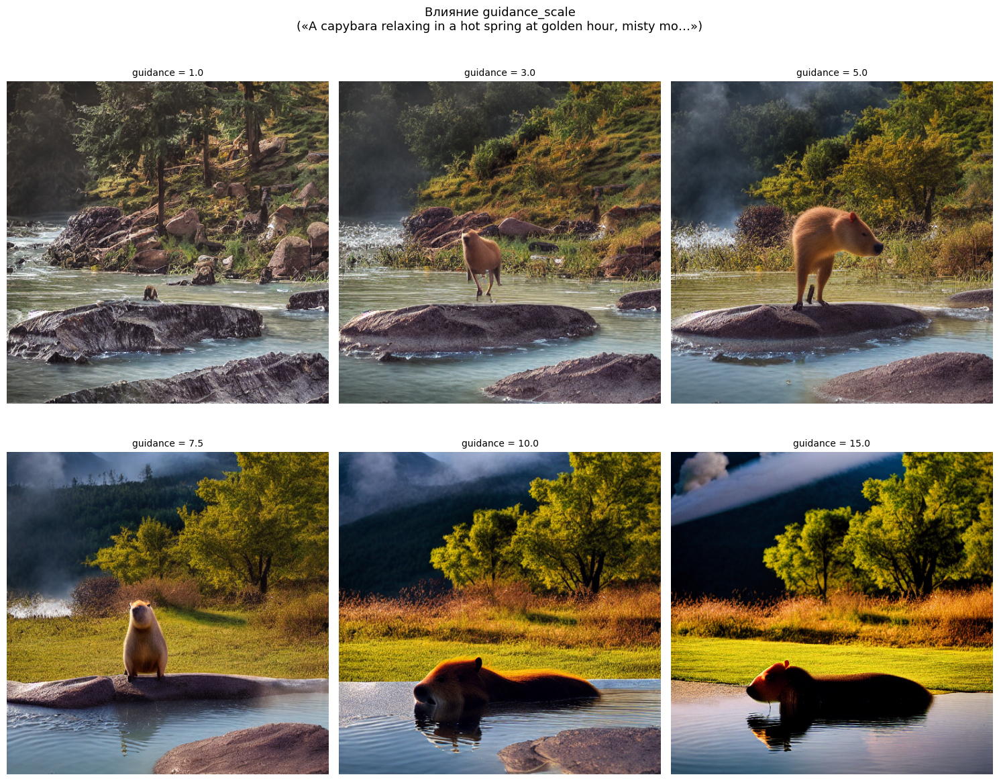

In [ ]:
test_prompt = ("A capybara relaxing in a hot spring at golden hour, "
               "misty mountains in the background, steam rising, "
               "photorealistic, National Geographic photo")

guidance_values = [1.0, 3.0, 5.0, 7.5, 10.0, 15.0]

images, titles = [], []
for g in guidance_values:
    print(f"guidance_scale = {g}")
    img = pipe(
        test_prompt,
        num_inference_steps=50,
        guidance_scale=g,
        generator=torch.Generator(device=DEVICE).manual_seed(123),
    ).images[0]
    img.save(OUTPUT_DIR / f"guidance_{g:.1f}.png")
    images.append(img)
    titles.append(f"guidance = {g}")

# Единственное изменение — увеличенный figsize
make_grid(images, cols=3, titles=titles, figsize=(15, 12.5),
          save_path=OUTPUT_DIR / "grid_guidance.png",
          suptitle=f"Влияние guidance_scale\n(«{test_prompt[:60]}…»)")

При значениях ниже 5.0 модель получает слишком много свободы, из-за чего теряет главный объект. При значениях выше 10.0 она слишком жестко следует тексту, что приводит к визуальной деградации, перенасыщению цветов и появлению артефактов.

Оптимум на 7.5: Это значение обеспечивает наилучший результат, позволяя точно интерпретировать сложные составные промпты без потери качества.

Влияние на композицию: Параметр меняет не только цвета, но и саму сцену. При низких значениях капибара стоит на камне, а при высоких — модель меняет её положение (она оказывается плывущей в воде).

### Исследование влияния количества шагов (num_inference_steps)

num_inference_steps = 10
num_inference_steps = 20
num_inference_steps = 30
num_inference_steps = 50
num_inference_steps = 75
num_inference_steps = 100


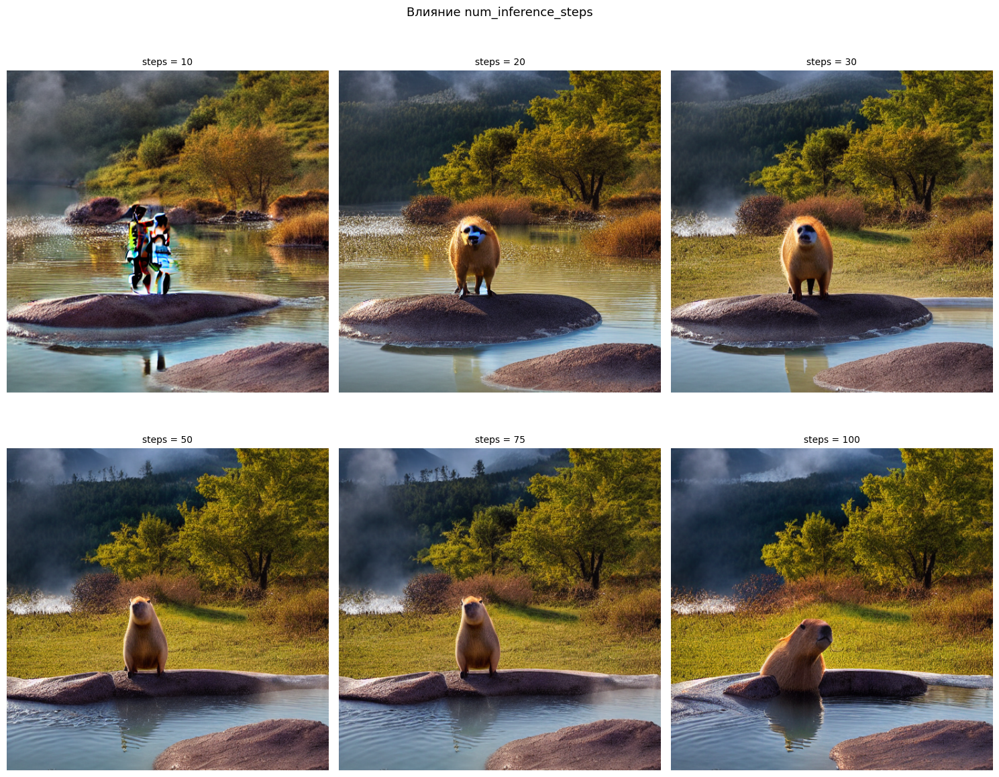

In [ ]:
step_values = [10, 20, 30, 50, 75, 100]

images, titles = [], []
for s in step_values:
    print(f"num_inference_steps = {s}")
    img = pipe(
        test_prompt,
        num_inference_steps=s,
        guidance_scale=7.5,
        generator=torch.Generator(device=DEVICE).manual_seed(123),
    ).images[0]
    img.save(OUTPUT_DIR / f"steps_{s:03d}.png")
    images.append(img)
    titles.append(f"steps = {s}")

# Увеличили figsize, чтобы tight_layout'у хватило места для заголовков
make_grid(images, cols=3, titles=titles, figsize=(15, 12.5),
          save_path=OUTPUT_DIR / "grid_steps.png",
          suptitle="Влияние num_inference_steps")

Для Stable Diffusion 1.5 минимально допустимым порогом является ~20 шагов. При меньших значениях модель не успевает выйти из состояния хаоса, и результат полностью разрушается.

Качество растет нелинейно. Самый большой прирост виден в диапазоне от 20 до 40 шагов. После достижения 50 шагов (порог насыщения) дальнейшее их увеличение не улучшает картинку, а лишь замедляет генерацию.

Большое количество шагов — это не просто «полировка» картинки. Как видно на 100 шагах, изменение траектории денойзинга может привести к изменению сцены (положение объекта).

In [ ]:
import gc, torch

# Удаляем SD-модель, чтобы освободитьвидеопамяти для DDPM
del pipe
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"Свободной памяти: {torch.cuda.mem_get_info()[0] / 1e9:.1f} GB")

Свободной памяти: 15.5 GB


## DDPM (Denoising Diffusion Probabilistic Models)

### Инициализация DDPM и архитектура модели

Архитектура TinyUNet

TinyUNet — это упрощенная U-Net, задача которой — предсказывать шум на зашумленном изображении. Временной шаг t преобразуется в вектор с помощью синусоидального позиционного кодирования (SinusoidalPosEmb) и внедряется в каждый блок, чтобы сеть «понимала» текущий уровень зашумления. Архитектура построена по принципу энкодера-декодера со сквозными соединениями (skip connections). Энкодер сжимает изображение с 28×28 до 7×7, наращивая число каналов до 128 через остаточные блоки (ResBlock) и слои пулинга. Декодер с помощью транспонированных сверток (ConvTranspose2d) восстанавливает исходное разрешение 28×28. Ключевая особенность — конкатенация признаков энкодера с признаками декодера на каждом уровне, что позволяет сохранить мелкие детали. Финальная свертка 1×1 сводит каналы обратно к одному и выдает итоговое предсказание шума.

In [ ]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
from tqdm.auto import tqdm
from IPython.display import display

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
T = 1000
BATCH_SIZE = 128
EPOCHS = 10
LR = 2e-4

# Расписание шума
betas = torch.linspace(1e-4, 0.02, T, device=DEVICE)
alphas = 1.0 - betas
alphas_cumprod = torch.cumprod(alphas, dim=0)
alphas_cumprod_prev = F.pad(alphas_cumprod[:-1], (1, 0), value=1.0)

sqrt_alphas_cumprod = torch.sqrt(alphas_cumprod)
sqrt_one_minus_alphas_cumprod = torch.sqrt(1.0 - alphas_cumprod)

def extract(a, t, x_shape):
    out = a.gather(0, t)
    return out.view(t.shape[0], *([1] * (len(x_shape) - 1)))

def q_sample(x0, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x0)
    a = extract(sqrt_alphas_cumprod, t, x0.shape)
    b = extract(sqrt_one_minus_alphas_cumprod, t, x0.shape)
    return a * x0 + b * noise

# Модель
class SinusoidalPosEmb(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
    def forward(self, x):
        half = self.dim // 2
        emb = math.log(10000) / (half - 1)
        emb = torch.exp(torch.arange(half, device=x.device) * -emb)
        emb = x[:, None] * emb[None, :]
        return torch.cat((emb.sin(), emb.cos()), dim=-1)

class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, tdim):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.norm1 = nn.GroupNorm(8, out_ch)
        self.norm2 = nn.GroupNorm(8, out_ch)
        self.tmlp = nn.Linear(tdim, out_ch)
    def forward(self, x, t):
        h = F.silu(self.norm1(self.conv1(x)))
        h = h + F.silu(self.tmlp(t))[:, :, None, None]
        return F.silu(self.norm2(self.conv2(h)))

class TinyUNet(nn.Module):
    def __init__(self, in_ch=1, base=32, tdim=128):
        super().__init__()
        self.tmlp = nn.Sequential(
            SinusoidalPosEmb(tdim),
            nn.Linear(tdim, tdim), nn.SiLU(),
            nn.Linear(tdim, tdim),
        )
        self.d1 = ResBlock(in_ch, base, tdim)
        self.p1 = nn.Conv2d(base, base, 4, 2, 1)
        self.d2 = ResBlock(base, base * 2, tdim)
        self.p2 = nn.Conv2d(base * 2, base * 2, 4, 2, 1)
        self.bot = ResBlock(base * 2, base * 4, tdim)
        self.u1 = nn.ConvTranspose2d(base * 4, base * 2, 4, 2, 1)
        self.r1 = ResBlock(base * 4, base * 2, tdim)
        self.u2 = nn.ConvTranspose2d(base * 2, base, 4, 2, 1)
        self.r2 = ResBlock(base * 2, base, tdim)
        self.out = nn.Conv2d(base, in_ch, 1)
    def forward(self, x, t):
        te = self.tmlp(t)
        h1 = self.d1(x, te)
        h2 = self.d2(self.p1(h1), te)
        b  = self.bot(self.p2(h2), te)
        u1 = self.u1(b)
        u1 = self.r1(torch.cat([u1, h2], 1), te)
        u2 = self.u2(u1)
        u2 = self.r2(torch.cat([u2, h1], 1), te)
        return self.out(u2)

# Данные
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])
train_ds = torchvision.datasets.MNIST("./data", train=True, download=True, transform=transform)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)

model = TinyUNet().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
print(f"Параметров в модели: {sum(p.numel() for p in model.parameters())/1e6:.2f} M")

Параметров в модели: 0.75 M


### Обучение DDPM и график Loss
Цикл обучения модели на датасете MNIST в течение 10 эпох.

Epoch 1/10:   0%|          | 0/469 [00:00<?, ?it/s]

  → средний loss эпохи: 0.0864


Epoch 2/10:   0%|          | 0/469 [00:00<?, ?it/s]

  → средний loss эпохи: 0.0374


Epoch 3/10:   0%|          | 0/469 [00:00<?, ?it/s]

  → средний loss эпохи: 0.0324


... (10 outputs left out)

Epoch 9/10:   0%|          | 0/469 [00:00<?, ?it/s]

  → средний loss эпохи: 0.0267


Epoch 10/10:   0%|          | 0/469 [00:00<?, ?it/s]

  → средний loss эпохи: 0.0261


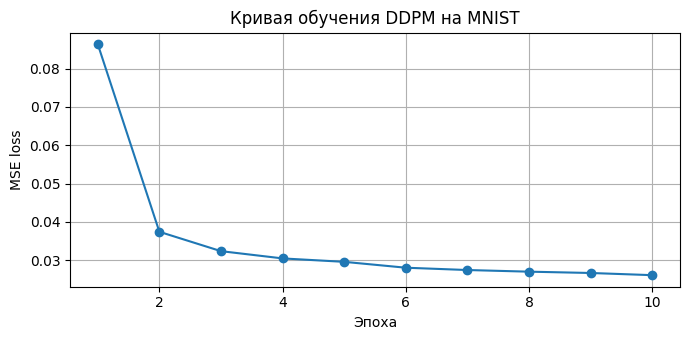

In [ ]:
loss_history = []
model.train()
for epoch in range(EPOCHS):
    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}")
    epoch_loss = 0.0
    for x, _ in pbar:
        x = x.to(DEVICE, non_blocking=True)
        t = torch.randint(0, T, (x.size(0),), device=DEVICE).long()
        noise = torch.randn_like(x)
        x_noisy = q_sample(x, t, noise)
        noise_pred = model(x_noisy, t)
        loss = F.mse_loss(noise_pred, noise)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
        pbar.set_postfix(loss=f"{loss.item():.4f}")
    avg = epoch_loss / len(train_loader)
    loss_history.append(avg)
    print(f"  → средний loss эпохи: {avg:.4f}")

# График loss
plt.figure(figsize=(7, 3.5))
plt.plot(range(1, EPOCHS + 1), loss_history, marker="o")
plt.xlabel("Эпоха"); plt.ylabel("MSE loss"); plt.grid(True)
plt.title("Кривая обучения DDPM на MNIST")
plt.tight_layout()
plt.savefig("ddpm_loss.png", dpi=140)
plt.show()

Плавное падение графика без скачков подтверждает высокую стабильность диффузионных моделей.

Loss не стремится к нулю, так как предсказать абсолютно случайный шум невозможно.


### Визуализация прямого процесса (зашумления)
Демонстрация того, как реальное изображение постепенно превращается в чистый шум.

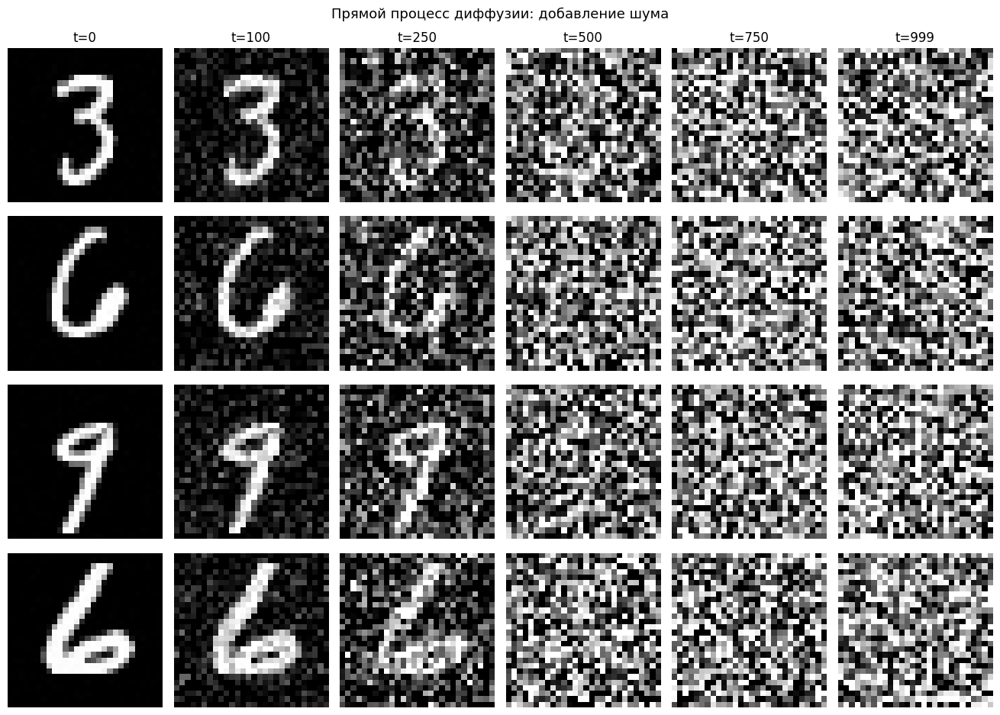

In [ ]:
@torch.no_grad()
def visualize_forward(n_images=4):
    model.eval()
    x0, _ = next(iter(DataLoader(train_ds, batch_size=n_images, shuffle=True)))
    x0 = x0.to(DEVICE)
    timesteps = [0, 100, 250, 500, 750, 999]
    fig, axes = plt.subplots(n_images, len(timesteps),
                             figsize=(2.2 * len(timesteps), 2.4 * n_images))
    for i in range(n_images):
        for j, tv in enumerate(timesteps):
            t = torch.tensor([tv], device=DEVICE).long()
            x_noisy = q_sample(x0[i:i+1], t)
            img = ((x_noisy[0, 0].cpu().numpy() + 1) / 2).clip(0, 1)
            axes[i, j].imshow(img, cmap="gray")
            axes[i, j].axis("off")
            if i == 0:
                axes[i, j].set_title(f"t={tv}")
    fig.suptitle("Прямой процесс диффузии: добавление шума", fontsize=13)
    plt.tight_layout()
    plt.savefig("ddpm_forward_process.png", dpi=140, bbox_inches="tight")
    plt.show()

visualize_forward(n_images=4)

Визуализация наглядно доказывает, что прямой процесс работает по принципу постепенного разрушения структуры данных. Модель не удаляет картинку сразу, а шаг за шагом заменяет её шумом.


### Визуализация обратного процесса (генерации)
Генерация новых цифр из чистого шума.

Sampling: 0it [00:00, ?it/s]

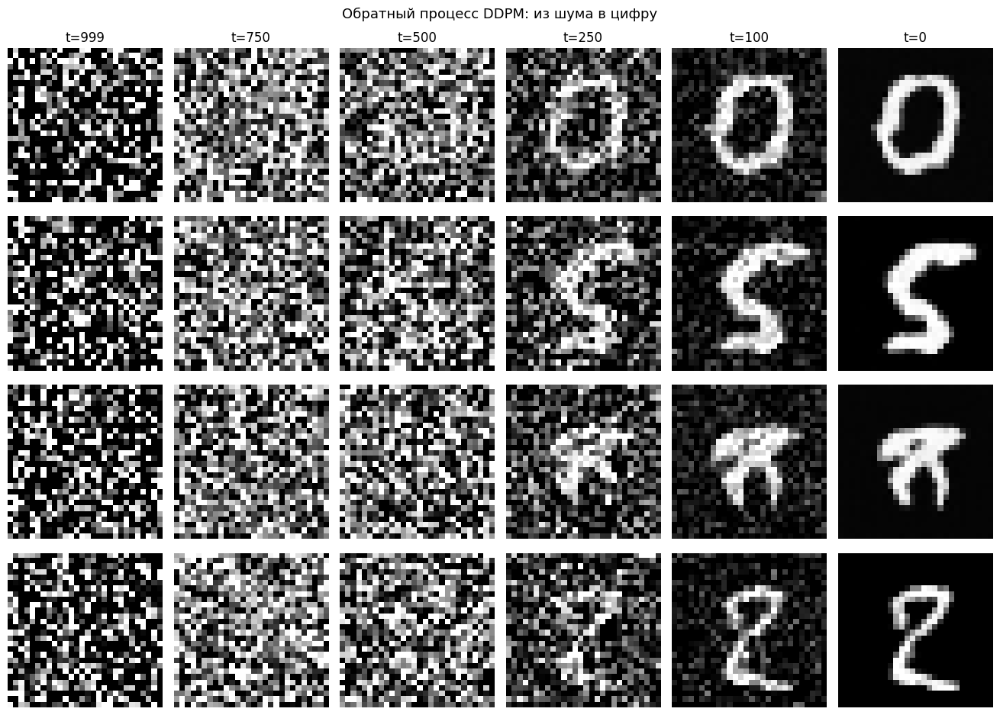

Sampling 8: 0it [00:00, ?it/s]

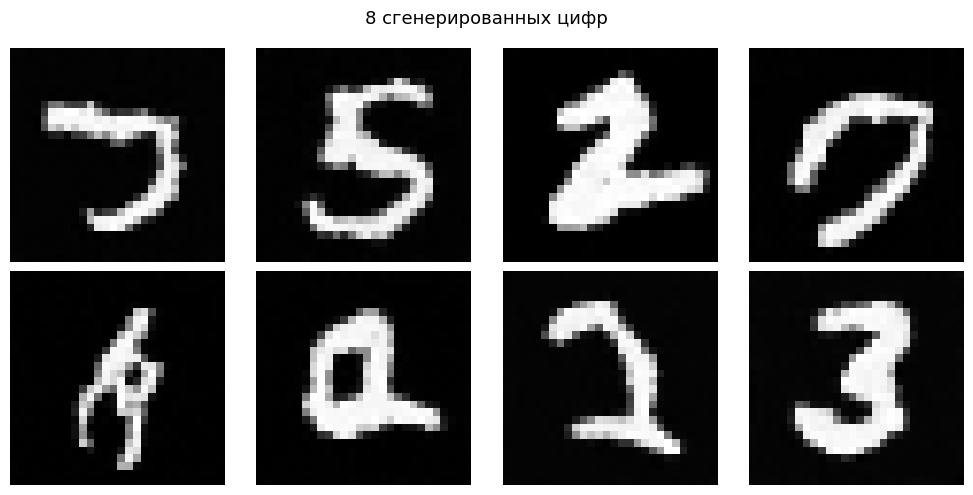

In [ ]:
@torch.no_grad()
def sample_with_snapshots(n_samples=4, snapshot_at=(999, 750, 500, 250, 100, 0)):
    model.eval()
    x = torch.randn(n_samples, 1, 28, 28, device=DEVICE)
    snapshots = {snapshot_at[0]: x.clone()}   # чистый шум (t=999)

    for t in tqdm(reversed(range(T)), desc="Sampling", leave=False):
        t_batch = torch.full((n_samples,), t, device=DEVICE).long()
        eps_hat = model(x, t_batch)

        a_t = alphas[t]
        a_bar = alphas_cumprod[t]
        b_t = betas[t]

        noise = torch.randn_like(x) if t > 0 else torch.zeros_like(x)
        x = (1 / torch.sqrt(a_t)) * (x - (b_t / torch.sqrt(1 - a_bar)) * eps_hat) \
            + torch.sqrt(b_t) * noise

        if t in snapshot_at:
            snapshots[t] = x.clone()

    x = (x.clamp(-1, 1) + 1) / 2

    ordered_t = list(snapshot_at)
    fig, axes = plt.subplots(n_samples, len(ordered_t),
                             figsize=(2.2 * len(ordered_t), 2.4 * n_samples))
    if n_samples == 1:
        axes = axes[None, :]
    for i in range(n_samples):
        for j, tv in enumerate(ordered_t):
            img = snapshots[tv][i, 0].cpu().numpy()
            img = ((img + 1) / 2 if tv != 999 else img).clip(0, 1)
            axes[i, j].imshow(img, cmap="gray")
            axes[i, j].axis("off")
            if i == 0:
                axes[i, j].set_title(f"t={tv}")
    fig.suptitle("Обратный процесс DDPM: из шума в цифру", fontsize=13)
    plt.tight_layout()
    plt.savefig("ddpm_reverse_process.png", dpi=140, bbox_inches="tight")
    plt.show()

    x_big = torch.randn(8, 1, 28, 28, device=DEVICE)
    for t in tqdm(reversed(range(T)), desc="Sampling 8", leave=False):
        tb = torch.full((8,), t, device=DEVICE).long()
        eps_hat = model(x_big, tb)
        a_t, a_bar, b_t = alphas[t], alphas_cumprod[t], betas[t]
        noise = torch.randn_like(x_big) if t > 0 else torch.zeros_like(x_big)
        x_big = (1 / torch.sqrt(a_t)) * (x_big - (b_t / torch.sqrt(1 - a_bar)) * eps_hat) \
                + torch.sqrt(b_t) * noise
    x_big = (x_big.clamp(-1, 1) + 1) / 2

    fig, axes = plt.subplots(2, 4, figsize=(10, 5))
    for i, ax in enumerate(axes.flatten()):
        ax.imshow(x_big[i, 0].cpu().numpy(), cmap="gray")
        ax.axis("off")
    fig.suptitle("8 сгенерированных цифр", fontsize=13)
    plt.tight_layout()
    plt.savefig("ddpm_generated_samples.png", dpi=140, bbox_inches="tight")
    plt.show()

sample_with_snapshots(n_samples=4)

DDPM успешно выучила распределение датасета MNIST. Она способна генерировать осмысленные изображения из абсолютного хаоса.

 Обратный процесс доказал, что модель сначала восстанавливает общие очертания (на средних шагах), и только на последних шагах (ближе к t=0) дорисовывает мелкие детали и убирает финальный шум.

## **1. Чем диффузионные модели отличаются от GAN?**
Процесс обучения: GAN обучаются через состязательную игру двух сетей (Генератора и Дискриминатора). Это сложный и нестабильный процесс, склонный к «коллапсу мод». Диффузионные модели обучаются решать задачу регрессии — предсказывать шум. Это делает обучение крайне стабильным.

Генерация: GAN генерируют изображение за один проход (очень быстро), но могут страдать от локальных артефактов. Диффузионные модели генерируют изображение итеративно (медленно), удаляя шум шаг за шагом, но обеспечивают лучшее покрытие распределения данных и высокое разнообразие.

Результат: GAN склонны пропускать некоторые моды (например, генерировать только один тип лиц), в то время как диффузионные модели лучше передают разнообразие тренировочного датасета.

## **2. Почему количество шагов важно для качества?**
В стандартном DDPM используется 1000 шагов. Каждый шаг удаляет лишь крошечную долю шума. Если шагов слишком мало (например, 10), модель не успевает сформировать структуру изображения — на выходе получается шум.
Однако после определенного порога (обычно 50–100 шагов для Stable Diffusion) качество выходит на плато. Дальнейшее увеличение шагов лишь замедляет генерацию, почти не улучшая картинку. Современные ускоренные сэмплеры (DDIM, DPM-Solver) позволяют сократить 1000 шагов до 20–30 без потери качества.

## **3. Какие ещё задачи можно решать диффузионными моделями?**
Помимо генерации картинок, диффузионные модели показали выдающиеся результаты в:

Генерации аудио и музыки (например, AudioLDM).

Генерации видео (Sora, Runway Gen-2).

Биологии и медицине (предсказание 3D-структуры белков — AlphaFold, генерация молекул для новых лекарств).

3D-моделировании (генерация 3D-объектов по тексту).

Решение обратных задач (удаление шума, восстановление старых фото — super-resolution, дорисовка недостающих частей — inpainting).

Прогнозировании временных рядов и обучении с подкреплением (Robotics).